# GCN 节点分类入门 — Cora 数据集

## 目标
使用 PyTorch Geometric (PyG) 实现一个 **2 层 GCN 模型**，在 Cora 引文网络数据集上进行节点分类。

这是图神经网络入门的**必跑项目**，完整展示了 GCN 的核心工作流程：
1. 加载图数据
2. 定义 GCN 模型
3. 训练与评估
4. 可视化分析

## Cora 数据集简介
- **节点数**: 2708 (科学论文)
- **边数**: 10556 (引用关系)
- **特征维度**: 1433 (词袋模型)
- **类别数**: 7
- **训练集**: 140 篇 (仅 5% 有标签 — 半监督学习)

In [11]:
import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
from torch_geometric.datasets import Planetoid
from torch_geometric.transforms import NormalizeFeatures
import matplotlib.pyplot as plt
import numpy as np

# 修复 matplotlib 中文显示问题
plt.rcParams['font.sans-serif'] = ['Heiti TC', 'PingFang HK', 'Kaiti SC']
plt.rcParams['axes.unicode_minus'] = False

# 设置随机种子保证可复现
torch.manual_seed(42)
np.random.seed(42)

print(f"PyTorch 版本: {torch.__version__}")
print(f"CUDA 可用: {torch.cuda.is_available()}")

PyTorch 版本: 2.13.0
CUDA 可用: False


## 1. 加载 Cora 数据集

In [3]:
# 加载数据集（自动下载到 data/Planetoid 目录）
dataset = Planetoid(root='../data/Planetoid', name='Cora', transform=NormalizeFeatures())
data = dataset[0]

print(f"=" * 50)
print(f"Cora 数据集信息")
print(f"=" * 50)
print(f"节点数:      {data.num_nodes:,}")
print(f"边数:        {data.num_edges:,}")
print(f"特征维度:    {dataset.num_features}")
print(f"类别数:      {dataset.num_classes}")
print(f"训练节点数:  {data.train_mask.sum().item():,}")
print(f"验证节点数:  {data.val_mask.sum().item():,}")
print(f"测试节点数:  {data.test_mask.sum().item():,}")
print(f"=" * 50)

# 查看一个样本
print(f"\n特征矩阵形状: {data.x.shape}")
print(f"边索引形状:    {data.edge_index.shape}")
print(f"标签分布:      {torch.bincount(data.y).tolist()}")

Cora 数据集信息
节点数:      2,708
边数:        10,556
特征维度:    1433
类别数:      7
训练节点数:  140
验证节点数:  500
测试节点数:  1,000

特征矩阵形状: torch.Size([2708, 1433])
边索引形状:    torch.Size([2, 10556])
标签分布:      [351, 217, 418, 818, 426, 298, 180]


## 2. 定义 GCN 模型

GCN 的核心：每一层做 **邻居聚合 + 特征变换**。

这里使用 2 层 GCN：
- 第 1 层：1433 → 16（聚合一度邻居信息）
- 第 2 层：16 → 7（聚合二度邻居信息 → 输出分类）

In [4]:
class GCN(torch.nn.Module):
    """2 层图卷积神经网络"""
    
    def __init__(self, num_features, hidden_channels, num_classes, dropout=0.5):
        super(GCN, self).__init__()
        self.conv1 = GCNConv(num_features, hidden_channels)  # 第 1 层
        self.conv2 = GCNConv(hidden_channels, num_classes)    # 第 2 层（输出层）
        self.dropout = dropout

    def forward(self, x, edge_index):
        # 第 1 层：邻居聚合 + 特征变换 → ReLU 激活 → Dropout
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        
        # 第 2 层：邻居聚合 + 特征变换 → log_softmax 输出
        x = self.conv2(x, edge_index)
        return F.log_softmax(x, dim=1)

# 创建模型
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = GCN(
    num_features=dataset.num_features,  # 1433
    hidden_channels=16,                  # 隐藏层维度
    num_classes=dataset.num_classes,     # 7
    dropout=0.5
).to(device)

print(f"使用设备: {device}")
print(f"模型参数数: {sum(p.numel() for p in model.parameters()):,}")
print(model)

使用设备: cpu
模型参数数: 23,063
GCN(
  (conv1): GCNConv(1433, 16)
  (conv2): GCNConv(16, 7)
)


## 3. 训练模型

In [5]:
# 数据移到设备
data = data.to(device)

# 优化器（Adam + L2 正则化）
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)

def train():
    """训练一个 step"""
    model.train()
    optimizer.zero_grad()
    out = model(data.x, data.edge_index)
    loss = F.nll_loss(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    return loss.item()

@torch.no_grad()
def test():
    """在训练/验证/测试集上评估"""
    model.eval()
    out = model(data.x, data.edge_index)
    pred = out.argmax(dim=1)
    
    train_acc = (pred[data.train_mask] == data.y[data.train_mask]).float().mean()
    val_acc = (pred[data.val_mask] == data.y[data.val_mask]).float().mean()
    test_acc = (pred[data.test_mask] == data.y[data.test_mask]).float().mean()
    return train_acc.item(), val_acc.item(), test_acc.item()

# 训练循环
print("开始训练...\n")
best_val_acc = 0
best_test_acc = 0
history = {'train_loss': [], 'train_acc': [], 'val_acc': [], 'test_acc': []}

for epoch in range(1, 201):
    loss = train()
    train_acc, val_acc, test_acc = test()
    
    history['train_loss'].append(loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)
    history['test_acc'].append(test_acc)
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_test_acc = test_acc
    
    if epoch % 20 == 0:
        print(f'Epoch {epoch:3d} | Loss: {loss:.4f} | '
              f'Train: {train_acc:.4f} | Val: {val_acc:.4f} | Test: {test_acc:.4f}')

print(f'\n最佳验证准确率: {best_val_acc:.4f}')
print(f'对应测试准确率: {best_test_acc:.4f}')

开始训练...

Epoch  20 | Loss: 1.7174 | Train: 0.8571 | Val: 0.5260 | Test: 0.5360
Epoch  40 | Loss: 1.3281 | Train: 0.9643 | Val: 0.7040 | Test: 0.7030
Epoch  60 | Loss: 0.9540 | Train: 0.9929 | Val: 0.7600 | Test: 0.7720
Epoch  80 | Loss: 0.6925 | Train: 0.9929 | Val: 0.7760 | Test: 0.7900
Epoch 100 | Loss: 0.5591 | Train: 0.9929 | Val: 0.7660 | Test: 0.7950
Epoch 120 | Loss: 0.4700 | Train: 0.9929 | Val: 0.7740 | Test: 0.8020
Epoch 140 | Loss: 0.4071 | Train: 0.9929 | Val: 0.7780 | Test: 0.8010
Epoch 160 | Loss: 0.3849 | Train: 1.0000 | Val: 0.7780 | Test: 0.8010
Epoch 180 | Loss: 0.3435 | Train: 1.0000 | Val: 0.7780 | Test: 0.8020
Epoch 200 | Loss: 0.3223 | Train: 1.0000 | Val: 0.7800 | Test: 0.7990

最佳验证准确率: 0.7840
对应测试准确率: 0.8060


## 4. 可视化训练曲线

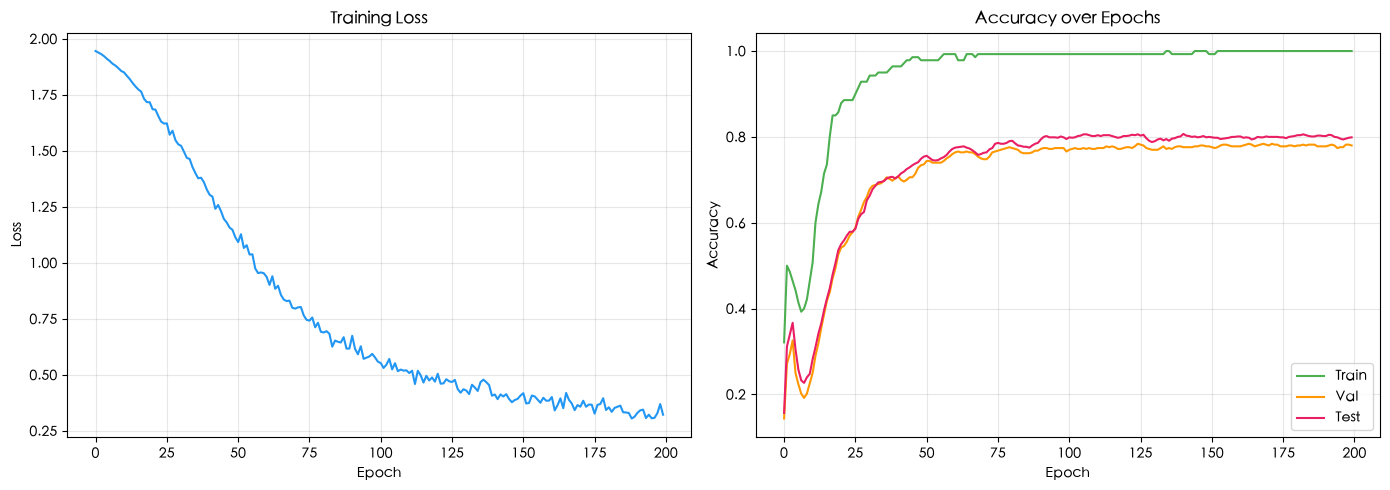

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss 曲线
axes[0].plot(history['train_loss'], color='#2196F3', linewidth=1.5)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training Loss')
axes[0].grid(True, alpha=0.3)

# Accuracy 曲线
axes[1].plot(history['train_acc'], label='Train', color='#4CAF50', linewidth=1.5)
axes[1].plot(history['val_acc'], label='Val', color='#FF9800', linewidth=1.5)
axes[1].plot(history['test_acc'], label='Test', color='#E91E63', linewidth=1.5)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy over Epochs')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 5. 节点嵌入可视化 (t-SNE)

抽取 GCN 第 1 层的输出（16 维嵌入），用 t-SNE 降维到 2 维，观察同类节点是否聚集。

正在进行 t-SNE 降维...


/Users/ziyi/Demo/1-AI/GCN-Fraud-Detection/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 33410 (\N{CJK UNIFIED IDEOGRAPH-8282}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/ziyi/Demo/1-AI/GCN-Fraud-Detection/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 28857 (\N{CJK UNIFIED IDEOGRAPH-70B9}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/ziyi/Demo/1-AI/GCN-Fraud-Detection/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 23884 (\N{CJK UNIFIED IDEOGRAPH-5D4C}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/ziyi/Demo/1-AI/GCN-Fraud-Detection/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 20837 (\N{CJK UNIFIED IDEOGRAPH-5165}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/ziyi/Demo/1-AI/GCN-Fr

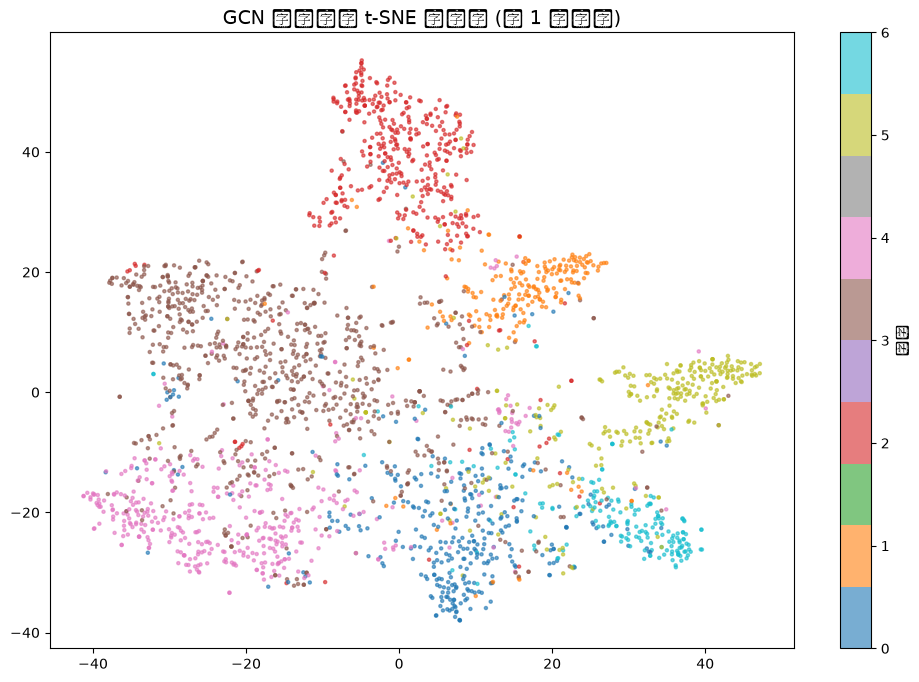

In [8]:
from sklearn.manifold import TSNE

# 获取第 1 层 GCN 输出的嵌入（16 维）
model.eval()
with torch.no_grad():
    x = model.conv1(data.x, data.edge_index)
    embeddings = F.relu(x).cpu().numpy()

# t-SNE 降维
print("正在进行 t-SNE 降维...")
tsne = TSNE(n_components=2, random_state=42, perplexity=50, max_iter=1000)
coords = tsne.fit_transform(embeddings)

# 可视化
fig, ax = plt.subplots(figsize=(12, 8))
scatter = ax.scatter(coords[:, 0], coords[:, 1], c=data.y.cpu().numpy(), 
                     cmap='tab10', alpha=0.6, s=5)
ax.set_title('GCN 节点嵌入 t-SNE 可视化 (第 1 层输出)', fontsize=14)
plt.colorbar(scatter, ax=ax, label='类别')
plt.show()

## 6. 对比实验：随机森林（只用节点特征，不用图结构）

这个对比实验展示了**图结构信息的价值**——GCN 使用了引用关系作为边信息，而随机森林只用论文本身的特征。

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# 准备数据
X = data.x.cpu().numpy()
y = data.y.cpu().numpy()
train_mask = data.train_mask.cpu().numpy()
test_mask = data.test_mask.cpu().numpy()

# 训练随机森林
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X[train_mask], y[train_mask])

# 预测和评估
rf_pred = rf.predict(X[test_mask])
rf_acc = accuracy_score(y[test_mask], rf_pred)
rf_f1 = f1_score(y[test_mask], rf_pred, average='macro')

print(f"随机森林 (只使用节点特征):")
print(f"  Test Accuracy: {rf_acc:.4f}")
print(f"  Test F1 (macro): {rf_f1:.4f}")

# GCN 的测试结果
model.eval()
with torch.no_grad():
    out = model(data.x, data.edge_index)
    gcn_pred = out.argmax(dim=1)
    gcn_acc = (gcn_pred[data.test_mask] == data.y[data.test_mask]).float().mean()
    gcn_f1 = 0  # 简化计算
    for c in range(dataset.num_classes):
        tp = ((gcn_pred[data.test_mask] == c) & (data.y[data.test_mask] == c)).sum().float()
        fp = ((gcn_pred[data.test_mask] == c) & (data.y[data.test_mask] != c)).sum().float()
        fn = ((gcn_pred[data.test_mask] != c) & (data.y[data.test_mask] == c)).sum().float()
        prec = tp / (tp + fp + 1e-8)
        rec = tp / (tp + fn + 1e-8)
        gcn_f1 += (2 * prec * rec / (prec + rec + 1e-8)).item()
    gcn_f1 /= dataset.num_classes

print(f"\nGCN (使用节点特征 + 图结构):")
print(f"  Test Accuracy: {gcn_acc:.4f}")
print(f"  Test F1 (macro): {gcn_f1:.4f}")

print(f"\n📊 GCN 相比随机森林的提升: Accuracy +{gcn_acc - rf_acc:.4f}, F1 +{gcn_f1 - rf_f1:.4f}")
print(f"\n💡 关键洞察: 图结构信息（论文之间的引用关系）提供了节点特征之外的重要信息！")
print(f"   在风控场景中，这意味着用户之间的关联关系（共用设备、IP等）蕴含了")
print(f"   单用户行为特征无法捕获的欺诈信号。")

随机森林 (只使用节点特征):
  Test Accuracy: 0.5850
  Test F1 (macro): 0.5839

GCN (使用节点特征 + 图结构):
  Test Accuracy: 0.7990
  Test F1 (macro): 0.7878

📊 GCN 相比随机森林的提升: Accuracy +0.2140, F1 +0.2040

💡 关键洞察: 图结构信息（论文之间的引用关系）提供了节点特征之外的重要信息！
   在风控场景中，这意味着用户之间的关联关系（共用设备、IP等）蕴含了
   单用户行为特征无法捕获的欺诈信号。


## 7. 实验：修改 GCN 结构观察效果变化

尝试不同的层数和隐藏层维度，看看模型效果如何变化。

In [10]:
def run_experiment(hidden_channels, num_layers, dropout, epochs=200):
    """跑一组实验配置"""
    class MultiLayerGCN(torch.nn.Module):
        def __init__(self):
            super().__init__()
            self.convs = torch.nn.ModuleList()
            self.convs.append(GCNConv(dataset.num_features, hidden_channels))
            for _ in range(num_layers - 2):
                self.convs.append(GCNConv(hidden_channels, hidden_channels))
            self.convs.append(GCNConv(hidden_channels, dataset.num_classes))
            self.dropout = dropout

        def forward(self, x, edge_index):
            for conv in self.convs[:-1]:
                x = conv(x, edge_index)
                x = F.relu(x)
                x = F.dropout(x, p=self.dropout, training=self.training)
            x = self.convs[-1](x, edge_index)
            return F.log_softmax(x, dim=1)
    
    m = MultiLayerGCN().to(device)
    opt = torch.optim.Adam(m.parameters(), lr=0.01, weight_decay=5e-4)
    
    best_val = 0
    best_test = 0
    for epoch in range(epochs):
        m.train()
        opt.zero_grad()
        out = m(data.x, data.edge_index)
        loss = F.nll_loss(out[data.train_mask], data.y[data.train_mask])
        loss.backward()
        opt.step()
        
        m.eval()
        with torch.no_grad():
            out = m(data.x, data.edge_index)
            pred = out.argmax(dim=1)
            val_acc = (pred[data.val_mask] == data.y[data.val_mask]).float().mean()
            test_acc = (pred[data.test_mask] == data.y[data.test_mask]).float().mean()
            if val_acc > best_val:
                best_val = val_acc.item()
                best_test = test_acc.item()
    return best_val, best_test

# 实验配置
configs = [
    (16, 2, 0.5, "2 层, 16 维 (baseline)"),
    (32, 2, 0.5, "2 层, 32 维"),
    (64, 2, 0.5, "2 层, 64 维"),
    (16, 3, 0.5, "3 层, 16 维"),
    (32, 3, 0.5, "3 层, 32 维"),
    (16, 4, 0.5, "4 层, 16 维 (可能过度平滑)"),
]

print(f"{'配置':<25s} {'Val Acc':>10s} {'Test Acc':>10s}")
print("-" * 47)
for hidden, layers, drop, label in configs:
    val_acc, test_acc = run_experiment(hidden, layers, drop)
    print(f"{label:<25s} {val_acc:10.4f} {test_acc:10.4f}")

print("\n💡 观察要点:")
print("  1. 适度增加隐藏层维度通常能提升效果")
print("  2. 层数过多（4层+）可能导致过度平滑(over-smoothing)，效果反而下降")
print("  3. 在风控场景中，通常 2-3 层 GCN 效果最好")

配置                           Val Acc   Test Acc
-----------------------------------------------
2 层, 16 维 (baseline)          0.7980     0.8210
2 层, 32 维                     0.8060     0.8080
2 层, 64 维                     0.8000     0.8220
3 层, 16 维                     0.7740     0.7630
3 层, 32 维                     0.8140     0.8010
4 层, 16 维 (可能过度平滑)            0.7440     0.7440

💡 观察要点:
  1. 适度增加隐藏层维度通常能提升效果
  2. 层数过多（4层+）可能导致过度平滑(over-smoothing)，效果反而下降
  3. 在风控场景中，通常 2-3 层 GCN 效果最好


## 关键要点总结

1. **GCN 每一层 = 邻居聚合 + 特征变换**
2. **只需 5% 有标签数据**即可训练出有效的分类器（半监督学习）
3. **图结构信息**提供了节点特征之外的额外信息——这对于识别团伙欺诈至关重要
4. 通常 **2-3 层 GCN** 效果最好，层数过多会导致过度平滑

> **下一步**：了解如何在风控场景中构建异构图，请参考 `02-风控异构图构建.ipynb`